In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!ls /content/drive/
!ls "/content/drive/MyDrive/"
!ls "/content/drive/Shared drives/"


MyDrive
'Colab Notebooks'   'Extracted Images (500)'  'Kavartti videos'
'Extracted Images'  'kavaratti videos_17-25'
ls: cannot access '/content/drive/Shared drives/': No such file or directory


In [ ]:
!ls "/content/drive/MyDrive/kavaratti videos_17-25"

10.MP4	18.MP4	1.MP4	21.MP4	23.MP4	25.MP4	3.MP4  5.MP4  7.MP4  9.MP4
17.MP4	19.MP4	20.MP4	22.MP4	24.MP4	2.MP4	4.MP4  6.MP4  8.MP4


In [ ]:
import glob

video_dir = "/content/drive/MyDrive/kavaratti videos_17-25"
video_files = sorted(glob.glob(video_dir + "/*.MP4"))

print("Found videos:", video_files)


Found videos: ['/content/drive/MyDrive/kavaratti videos_17-25/1.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/10.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/17.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/18.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/19.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/2.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/20.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/21.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/22.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/23.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/24.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/25.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/3.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/4.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/5.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/6.MP4', '/content/drive/MyDrive/kavaratti videos_17-25/7.MP4', '/content/drive/MyDrive/kavaratti videos

In [ ]:
!pip install ultralytics opencv-python-headless git+https://github.com/facebookresearch/segment-anything.git numpy pandas

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-1keyumz1
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-1keyumz1
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 28.4 MB/s eta 0:00:00
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36592 sha256=b091a98bde51117c2390d967a3756cdef55c4306a311fa0bad7129a0515b48ce
  Stored in directory: /tmp/pip-ephem-wheel-cache-fzq4l08o/wheels/29/82/ff/04e2be9805a1cb48bec0b85b5a6da6b63f647645750a0e42d4
Successfully built segment_anything


In [ ]:
import ultralytics, cv2, numpy, pandas
import segment_anything
print("✅ All dependencies installed successfully!")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ All dependencies installed successfully!


In [ ]:
import os

# Base project path inside your Google Drive
project_path = "/content/drive/MyDrive/CoralBleaching_Project"

# Subfolders for organization
folders = [
    "datasets",       # training images & labels
    "videos",         # raw coral reef videos
    "checkpoints",    # YOLO / Segmentation model weights
    "results",        # output masks, bleaching percentage csv
    "notebooks"       # optional: keep .ipynb files
]

# Create folders if they don't already exist
for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("✅ Project structure created at:", project_path)


✅ Project structure created at: /content/drive/MyDrive/CoralBleaching_Project


In [ ]:
import os

base_path = "/content/drive/MyDrive/CoralBleaching_Project/datasets/raw"

folders = ["bleached", "healthy"]

for folder in folders:
    os.makedirs(os.path.join(base_path, folder), exist_ok=True)

print("✅ Dataset input folders ready at:", base_path)


✅ Dataset input folders ready at: /content/drive/MyDrive/CoralBleaching_Project/datasets/raw


In [ ]:
!pip install matplotlib


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from segment_anything import SamAutomaticMaskGenerator, sam_model_registry

print("✅ All dependencies installed and imported successfully!")


✅ All dependencies installed and imported successfully!


In [ ]:
# Step 3 - Load Segment Anything (SAM) Model

# 1. Download pretrained SAM checkpoint (ViT-B variant)
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -O sam_vit_b.pth

# 2. Import SAM modules
from segment_anything import SamAutomaticMaskGenerator, sam_model_registry

# 3. Set checkpoint path & model type
sam_checkpoint = "sam_vit_b.pth"
model_type = "vit_b"

# 4. Load the SAM model
sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)

# 5. Create a mask generator
mask_generator = SamAutomaticMaskGenerator(sam)

print("✅ SAM model loaded and ready for mask generation!")


✅ SAM model loaded and ready for mask generation!


In [ ]:
import os
import cv2
import numpy as np

# Function: Generate YOLOv8 segmentation masks + labels
def generate_yolo_masks(img_path, class_id, save_img_dir, save_label_dir):
    # 1. Read and convert image
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. Generate masks with SAM
    masks = mask_generator.generate(img_rgb)

    # 3. Pick the largest mask (avoid background/sand noise)
    if not masks:
        print(f"⚠️ No mask found for {img_path}")
        return
    best_mask = max(masks, key=lambda x: x['area'])['segmentation']

    # 4. Save masked image (visual check)
    mask_vis = img_rgb.copy()
    mask_vis[~best_mask] = 0
    out_img_path = os.path.join(save_img_dir, os.path.basename(img_path))
    cv2.imwrite(out_img_path, cv2.cvtColor(mask_vis, cv2.COLOR_RGB2BGR))

    # 5. Convert mask → polygon → YOLO format
    contours, _ = cv2.findContours(
        best_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        print(f"⚠️ No contour found for {img_path}")
        return

    h, w = img.shape[:2]
    label_path = os.path.join(
        save_label_dir,
        os.path.splitext(os.path.basename(img_path))[0] + ".txt"
    )
    with open(label_path, "w") as f:
        for cnt in contours:
            polygon = []
            for p in cnt:
                x, y = p[0]
                polygon.append(x / w)  # normalize x
                polygon.append(y / h)  # normalize y
            # Write only if polygon has at least 3 points (6 coords)
            if len(polygon) >= 6:
                f.write(f"{class_id} " + " ".join(map(str, polygon)) + "\n")

    print(f"✅ Processed {img_path} → {out_img_path}, {label_path}")


In [ ]:
!pip install tqdm


In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
!nvidia-smi

CUDA available: True
Sun Sep 14 14:05:53 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       2MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------------------

In [ ]:
import cv2
import torch
import numpy as np
import os
from tqdm import tqdm

# Resize utility
def resize_for_sam(img, max_dim=1024):
    h, w = img.shape[:2]
    scale = max_dim / max(h, w)
    if scale < 1:
        img = cv2.resize(img, (int(w*scale), int(h*scale)), interpolation=cv2.INTER_AREA)
    return img

# Updated generate_yolo_masks
def generate_yolo_masks(img_path, class_id, save_img_dir, save_label_dir):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize
    img_rgb = resize_for_sam(img_rgb)

    # Ensure SAM is on GPU
    sam.to("cuda")

    # Generate masks
    masks = mask_generator.generate(img_rgb)
    if not masks:
        print(f"⚠️ No mask found: {img_path}")
        return

    # Pick largest mask
    best_mask = max(masks, key=lambda x: x['area'])['segmentation']

    # Save visualization
    mask_vis = img_rgb.copy()
    mask_vis[~best_mask] = 0
    out_img_path = os.path.join(save_img_dir, os.path.basename(img_path))
    cv2.imwrite(out_img_path, cv2.cvtColor(mask_vis, cv2.COLOR_RGB2BGR))

    # Convert mask → polygon → YOLO format
    contours, _ = cv2.findContours(best_mask.astype(np.uint8),
                                   cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        print(f"⚠️ No contour: {img_path}")
        return

    h, w = img.shape[:2]
    label_path = os.path.join(save_label_dir, os.path.splitext(os.path.basename(img_path))[0] + ".txt")
    with open(label_path, "w") as f:
        for cnt in contours:
            polygon = []
            for p in cnt:
                x, y = p[0]
                polygon.append(x / w)
                polygon.append(y / h)
            if len(polygon) >= 6:
                f.write(f"{class_id} " + " ".join(map(str, polygon)) + "\n")

    print(f"✅ Processed: {img_path}")

# Paths
base_path = "/content/drive/MyDrive/CoralBleaching_Project/datasets"
raw_path = os.path.join(base_path, "raw")
images_out = os.path.join(base_path, "images")
labels_out = os.path.join(base_path, "labels")
os.makedirs(images_out, exist_ok=True)
os.makedirs(labels_out, exist_ok=True)

# Prepare list of images
bleached_imgs = [f for f in os.listdir(os.path.join(raw_path, "bleached")) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
healthy_imgs = [f for f in os.listdir(os.path.join(raw_path, "healthy")) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

all_imgs = [(f, 0, "bleached") for f in bleached_imgs] + [(f, 1, "healthy") for f in healthy_imgs]

# Loop with tqdm
for img_name, class_id, folder in tqdm(all_imgs, desc="Processing images"):
    img_path = os.path.join(raw_path, folder, img_name)
    generate_yolo_masks(img_path, class_id, images_out, labels_out)


Processing images:   0%|          | 1/303 [00:05<29:02,  5.77s/it]

✅ Processed: /content/drive/MyDrive/CoralBleaching_Project/datasets/raw/bleached/144.png


Processing images:   1%|          | 2/303 [00:10<26:10,  5.22s/it]

✅ Processed: /content/drive/MyDrive/CoralBleaching_Project/datasets/raw/bleached/142.png


Processing images:   1%|          | 3/303 [00:14<23:21,  4.67s/it]

✅ Processed: /content/drive/MyDrive/CoralBleaching_Project/datasets/raw/bleached/140.png


... (596 outputs left out)

Processing images: 100%|█████████▉| 302/303 [24:37<00:05,  5.37s/it]

✅ Processed: /content/drive/MyDrive/CoralBleaching_Project/datasets/raw/healthy/202.png


Processing images: 100%|██████████| 303/303 [24:42<00:00,  4.89s/it]

✅ Processed: /content/drive/MyDrive/CoralBleaching_Project/datasets/raw/healthy/200.png


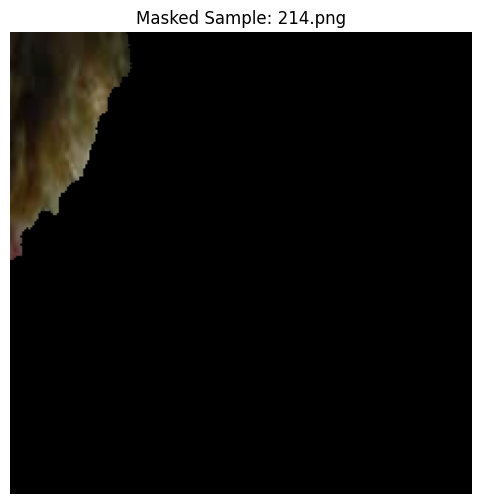

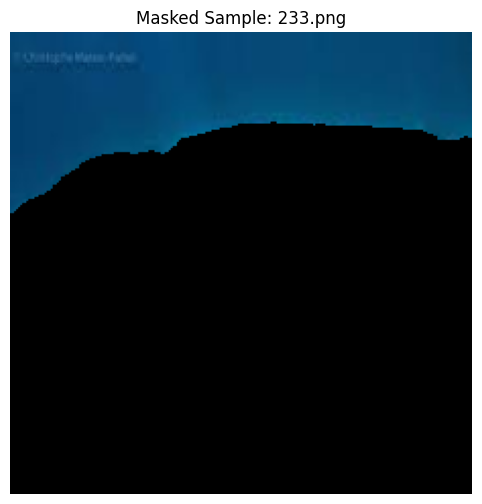

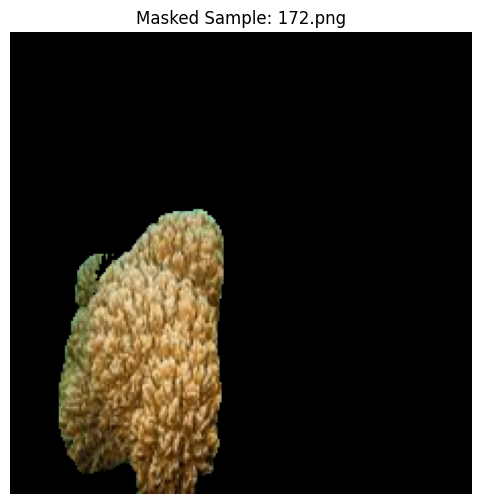

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

# Step 6 - Verify a few masked images

# Path where your processed images are saved
images_out = "/content/drive/MyDrive/CoralBleaching_Project/datasets/images"

# List all processed images
all_images = [f for f in os.listdir(images_out) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

# Pick 3 random images to check
sample_images = random.sample(all_images, min(3, len(all_images)))

for sample_img in sample_images:
    img_path = os.path.join(images_out, sample_img)
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(img_rgb)
    plt.title(f"Masked Sample: {sample_img}")
    plt.axis("off")
    plt.show()


In [ ]:
!pip install ultralytics --upgrade


In [ ]:
import yaml
import os

# Path to your dataset folder
dataset_path = "/content/drive/MyDrive/CoralBleaching_Project/datasets"

# Create the dataset.yaml content
dataset_yaml = {
    "path": dataset_path,       # base dataset folder
    "train": "images",          # folder with training images
    "val": "images",            # folder with validation images (using same for now)
    "nc": 2,                    # number of classes
    "names": ["bleached_coral", "healthy_coral"]  # class names
}

# Write YAML file
yaml_file_path = os.path.join(dataset_path, "dataset.yaml")
with open(yaml_file_path, "w") as f:
    yaml.dump(dataset_yaml, f)

print(f"✅ dataset.yaml created at: {yaml_file_path}")


✅ dataset.yaml created at: /content/drive/MyDrive/CoralBleaching_Project/datasets/dataset.yaml


In [ ]:
from ultralytics import YOLO
import os

# Path to your dataset.yaml
dataset_path = "/content/drive/MyDrive/CoralBleaching_Project/datasets"
dataset_yaml = os.path.join(dataset_path, "dataset.yaml")

# Step 1: Load pretrained YOLOv8 segmentation model
model = YOLO("yolov8s-seg.pt")  # small segmentation model, fast for fine-tuning

# Step 2: Train on your coral dataset
model.train(
    data=dataset_yaml,                        # path to dataset.yaml
    epochs=100,                               # number of training epochs
    imgsz=640,                                # input image size (resize to 640x640)
    batch=4,                                  # batch size (adjust based on GPU memory)
    save=True,                                # save checkpoints automatically
    project="/content/drive/MyDrive/CoralBleaching_Project/checkpoints",  # save location
    name="yolov8_coral_seg",                  # name for this training run
    verbose=True                              # show training progress in console
)


Ultralytics 8.3.199 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/CoralBleaching_Project/datasets/dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov8_coral_seg, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=T

/usr/local/lib/python3.12/dist-packages/ultralytics/nn/modules/block.py:1357: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:233.)
  attn = (q.transpose(-2, -1) @ k) * self.scale
/usr/local/lib/python3.12/dist-packages/ultralytics/nn/modules/block.py:1359: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic 

AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.5±0.2 ms, read: 8.6±14.2 MB/s, size: 23.8 KB)
train: Scanning /content/drive/MyDrive/CoralBleaching_Project/datasets/labels... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191 163.4it/s 1.2s
train: New cache created: /content/drive/MyDrive/CoralBleaching_Project/datasets/labels.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.9±0.4 ms, read: 9.3±9.6 MB/s, size: 20.7 KB)
val: Scanning /content/drive/MyDrive/CoralBleaching_Project/datasets/labels.cache... 191 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 191/191 71.0Kit/s 0.0s
Plotting labels to /content/drive/MyDrive/CoralBleaching_Project/checkpoints/yolov8_coral_seg/labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' a

/usr/local/lib/python3.12/dist-packages/ultralytics/utils/loss.py:240: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:233.)
  pred_dist = pred_dist.view(b, a, 4, c // 4).softmax(3).matmul(self.proj.type(pred_dist.dtype))
/usr/local/lib/python3.12/dist-packages/torch/functional.py:422: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this op

      1/100      3.86G      2.193      4.502       5.92      1.672          8        640: 0% ──────────── 0/48  2.6s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:829: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:233.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (395 outputs left out)

/usr/local/lib/python3.12/dist-packages/ultralytics/utils/loss.py:240: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:233.)
  pred_dist = pred_dist.view(b, a, 4, c // 4).softmax(3).matmul(self.proj.type(pred_dist.dtype))
/usr/local/lib/python3.12/dist-packages/torch/functional.py:422: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this op

    100/100       4.2G     0.4177     0.3602     0.7957     0.9835          3        640: 100% ━━━━━━━━━━━━ 48/48 4.7it/s 10.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 1.8it/s 0.2s<12.6s

/usr/local/lib/python3.12/dist-packages/ultralytics/utils/ops.py:545: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#results-reproducibility (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:233.)
  masks = (masks_in @ protos.float().view(c, -1)).view(-1, mh, mw)  # CHW
/usr/local/lib/python3.12/dist-packages/ultralytics/utils/metrics.py:164: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not 

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 7.5it/s 3.2s
                   all        191        230      0.846      0.808      0.871      0.801      0.846      0.808      0.876      0.793

100 epochs completed in 0.370 hours.
Optimizer stripped from /content/drive/MyDrive/CoralBleaching_Project/checkpoints/yolov8_coral_seg/weights/last.pt, 23.9MB
Optimizer stripped from /content/drive/MyDrive/CoralBleaching_Project/checkpoints/yolov8_coral_seg/weights/best.pt, 23.9MB

Validating /content/drive/MyDrive/CoralBleaching_Project/checkpoints/yolov8_coral_seg/weights/best.pt...
Ultralytics 8.3.199 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,780,374 parameters, 0 gradients, 39.9 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 1

In [ ]:
import os

ckpt_dir = "/content/drive/MyDrive/CoralBleaching_Project/checkpoints/yolov8_coral_seg"
print("Files in checkpoint folder:")
print(os.listdir(ckpt_dir))


Files in checkpoint folder:
['weights', 'args.yaml', 'labels.jpg', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'results.csv', 'train_batch4320.jpg', 'train_batch4321.jpg', 'train_batch4322.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch2_labels.jpg', 'val_batch1_labels.jpg', 'val_batch2_pred.jpg', 'val_batch1_pred.jpg', 'BoxPR_curve.png', 'BoxF1_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'MaskPR_curve.png', 'MaskF1_curve.png', 'MaskP_curve.png', 'MaskR_curve.png', 'confusion_matrix_normalized.png', 'confusion_matrix.png', 'results.png']



image 1/1 /content/drive/MyDrive/CoralBleaching_Project/datasets/images/144.png: 640x640 1 bleached_coral, 1 healthy_coral, 20.9ms
Speed: 2.9ms preprocess, 20.9ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/segment/predict2


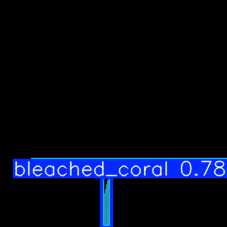

In [ ]:
# Step 4 – Verify YOLOv8 Model on Sample Images
from ultralytics import YOLO
import matplotlib.pyplot as plt
import os

# 1️⃣ Path to your trained YOLOv8 weights
checkpoint_path = "/content/drive/MyDrive/CoralBleaching_Project/checkpoints/yolov8_coral_seg/weights/best.pt"

# 2️⃣ Load the YOLOv8 segmentation model
model = YOLO(checkpoint_path)

# 3️⃣ Path to your images folder
images_folder = "/content/drive/MyDrive/CoralBleaching_Project/datasets/images"

# 4️⃣ Automatically pick the first image in the folder
sample_img = os.path.join(images_folder, os.listdir(images_folder)[0])

# 5️⃣ Run prediction on the sample image
results = model.predict(sample_img, save=True)

# 6️⃣ Display the prediction result (corrected for list output)
results[0].show()  # access the first Results object


In [ ]:
import os

# 1️⃣ Define your main project folder on Google Drive
project_path = "/content/drive/MyDrive/CoralBleaching_Project"

# 2️⃣ Path to your video files
videos_path = os.path.join(project_path, "videos")

# 3️⃣ Path to temporary folder where extracted frames will be saved
frames_path = os.path.join(project_path, "temp_frames")

# 4️⃣ Create the temp_frames folder if it doesn't exist already
os.makedirs(frames_path, exist_ok=True)

# 5️⃣ Print paths to verify
print("Project Path:", project_path)
print("Videos Path:", videos_path)
print("Frames Path:", frames_path)
print("✅ Paths are set and temp_frames folder is ready")


Project Path: /content/drive/MyDrive/CoralBleaching_Project
Videos Path: /content/drive/MyDrive/CoralBleaching_Project/videos
Frames Path: /content/drive/MyDrive/CoralBleaching_Project/temp_frames
✅ Paths are set and temp_frames folder is ready


In [ ]:
import os
import cv2

# ✅ Step 1 – Paths
project_path = "/content/drive/MyDrive/CoralBleaching_Project"
frames_path = os.path.join(project_path, "temp_frames")
os.makedirs(frames_path, exist_ok=True)

videos_path = "/content/drive/MyDrive/kavaratti videos_17-25"

# 🔹 Step 2 – Function to Extract Frames at Fixed Interval
def extract_frames(video_file, save_dir, fps=1):
    """
    Extract frames from a video at a fixed interval (fps=1 means 1 frame per second)
    """
    cap = cv2.VideoCapture(video_file)
    if not cap.isOpened():
        print("❌ Error opening video:", video_file)
        return

    video_fps = cap.get(cv2.CAP_PROP_FPS)  # original fps
    frame_interval = max(int(video_fps / fps), 1)  # avoid division by zero

    count = 0
    saved_count = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if count % frame_interval == 0:
            frame_filename = os.path.join(
                save_dir,
                f"{os.path.splitext(os.path.basename(video_file))[0]}_frame{saved_count:04d}.jpg"
            )
            cv2.imwrite(frame_filename, frame)
            saved_count += 1

        count += 1

    cap.release()
    print(f"✅ Extracted {saved_count} frames from {os.path.basename(video_file)}")


# 🔹 Step 3 – Extract Frames from All Videos
video_files = [v for v in os.listdir(videos_path) if v.lower().endswith((".mp4", ".avi", ".mov"))]

if not video_files:
    print("⚠️ No video files found in", videos_path)
else:
    for video in video_files:
        extract_frames(os.path.join(videos_path, video), frames_path, fps=1)


✅ Extracted 16 frames from 17.MP4
✅ Extracted 68 frames from 18.MP4
✅ Extracted 45 frames from 19.MP4
✅ Extracted 41 frames from 20.MP4
✅ Extracted 29 frames from 21.MP4
✅ Extracted 55 frames from 22.MP4
✅ Extracted 65 frames from 23.MP4
✅ Extracted 66 frames from 24.MP4
✅ Extracted 60 frames from 25.MP4
✅ Extracted 20 frames from 3.MP4
✅ Extracted 76 frames from 6.MP4
✅ Extracted 62 frames from 10.MP4
✅ Extracted 82 frames from 8.MP4
✅ Extracted 87 frames from 1.MP4
✅ Extracted 100 frames from 4.MP4
✅ Extracted 23 frames from 9.MP4
✅ Extracted 117 frames from 7.MP4
✅ Extracted 34 frames from 5.MP4
✅ Extracted 20 frames from 2.MP4


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO

# ✅ Step 1 – Paths
project_path = "/content/drive/MyDrive/CoralBleaching_Project"
frames_path = os.path.join(project_path, "temp_frames")
results_path = os.path.join(project_path, "results")
os.makedirs(results_path, exist_ok=True)

# Correct path to best.pt inside "weights"
model_path = os.path.join(project_path, "checkpoints/yolov8_coral_seg/weights/best.pt")

# ✅ Step 2 – Load YOLOv8 model
if not os.path.exists(model_path):
    raise FileNotFoundError(f"❌ best.pt not found at {model_path}")
model = YOLO(model_path)
print("✅ Model loaded:", model_path)

# ✅ Step 3 – Function to compute bleaching % for one frame
def compute_bleaching_percentage(frame_path, model):
    """
    Run YOLOv8 segmentation on a frame,
    count bleached vs healthy pixels,
    return bleaching percentage.
    """
    results = model.predict(frame_path, verbose=False)

    if results[0].masks is None:  # no detections
        return 0.0

    masks = results[0].masks.data.cpu().numpy()   # (num_masks, H, W)
    classes = results[0].boxes.cls.cpu().numpy()  # class IDs

    bleached_pixels = 0
    healthy_pixels = 0

    for i, mask in enumerate(masks):
        class_id = int(classes[i])
        num_pixels = int(mask.sum())
        if class_id == 0:  # bleached_coral
            bleached_pixels += num_pixels
        elif class_id == 1:  # healthy_coral
            healthy_pixels += num_pixels

    total = bleached_pixels + healthy_pixels
    if total == 0:
        return 0.0

    return (bleached_pixels / total) * 100


# ✅ Step 4 – Process all frames
results_list = []

for frame_file in sorted(os.listdir(frames_path)):
    if frame_file.endswith(".jpg"):
        frame_path = os.path.join(frames_path, frame_file)
        bleaching_percent = compute_bleaching_percentage(frame_path, model)
        results_list.append({
            "frame": frame_file,
            "bleaching_percent": bleaching_percent
        })

# ✅ Step 5 – Save results to CSV
df = pd.DataFrame(results_list)
csv_path = os.path.join(results_path, "frame_bleaching_percent.csv")
df.to_csv(csv_path, index=False)

print("✅ Bleaching % per frame saved to:", csv_path)
print(df.head())  # preview first few rows


✅ Model loaded: /content/drive/MyDrive/CoralBleaching_Project/checkpoints/yolov8_coral_seg/weights/best.pt
✅ Bleaching % per frame saved to: /content/drive/MyDrive/CoralBleaching_Project/results/frame_bleaching_percent.csv
              frame  bleaching_percent
0  10_frame0000.jpg           0.000000
1  10_frame0001.jpg           0.000000
2  10_frame0002.jpg           0.000000
3  10_frame0003.jpg          50.236223
4  10_frame0004.jpg          50.126642


In [ ]:
from google.colab import drive

# Mount to a fresh folder
drive.mount('/content/drive2')


Mounted at /content/drive2


In [ ]:
import os

frames_path = "/content/drive2/MyDrive/CoralBleaching_Project/temp_frames"

if os.path.exists(frames_path):
    print("✅ temp_frames folder found!")
    print("First 10 files:", os.listdir(frames_path)[:10])
else:
    print("❌ temp_frames folder not found. Please check the exact folder path in Drive.")


✅ temp_frames folder found!
First 10 files: ['18_frame0050.jpg', '18_frame0051.jpg', '18_frame0052.jpg', '18_frame0053.jpg', '18_frame0054.jpg', '18_frame0055.jpg', '18_frame0056.jpg', '18_frame0057.jpg', '18_frame0058.jpg', '18_frame0059.jpg']


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =======================
# Paths
# =======================
project_path = "/content/drive2/MyDrive/CoralBleaching_Project"
results_path = os.path.join(project_path, "results")
hsv_path = os.path.join(results_path, "hsv_baseline")
os.makedirs(hsv_path, exist_ok=True)

frames_path = "/content/drive2/MyDrive/CoralBleaching_Project/temp_frames"
print("✅ Using frames from:", frames_path)

# =======================
# HSV Thresholds
# =======================
# White-ish range → bleached coral
lower_bleached = np.array([0, 0, 180])
upper_bleached = np.array([180, 60, 255])

# Brown-ish range → healthy coral
lower_healthy = np.array([10, 80, 50])
upper_healthy = np.array([30, 255, 200])

# =======================
# Function to calculate bleaching %
# =======================
def analyze_frame(frame_path):
    img = cv2.imread(frame_path)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    mask_bleached = cv2.inRange(hsv, lower_bleached, upper_bleached)
    mask_healthy = cv2.inRange(hsv, lower_healthy, upper_healthy)

    bleached_pixels = np.sum(mask_bleached > 0)
    healthy_pixels = np.sum(mask_healthy > 0)

    total = bleached_pixels + healthy_pixels
    if total == 0:
        bleaching_percent = 0
    else:
        bleaching_percent = (bleached_pixels / total) * 100

    return bleaching_percent

# =======================
# Process all frames
# =======================
data = []
for frame_file in sorted(os.listdir(frames_path)):
    if frame_file.endswith((".jpg", ".png")):
        frame_path = os.path.join(frames_path, frame_file)
        bleaching_percent = analyze_frame(frame_path)
        data.append({"frame": frame_file, "bleaching_percent": bleaching_percent})

# Save table
df = pd.DataFrame(data)
csv_path = os.path.join(hsv_path, "hsv_bleaching_percent.csv")
df.to_csv(csv_path, index=False)
print("✅ HSV bleaching % per frame saved to:", csv_path)

# =======================
# Create pie charts per video
# =======================
df["video"] = df["frame"].apply(lambda x: x.split("_frame")[0])  # group by video name

for video, group in df.groupby("video"):
    mean_bleach = group["bleaching_percent"].mean()
    mean_healthy = 100 - mean_bleach

    plt.figure(figsize=(5, 5))
    plt.pie(
        [mean_bleach, mean_healthy],
        labels=["Bleached", "Healthy"],
        colors=["#FFFDD0", "#8B4513"],  # cream + brown
        autopct="%.1f%%",
    )
    plt.title(f"Bleaching in {video}")
    pie_path = os.path.join(hsv_path, f"{video}_pie.png")
    plt.savefig(pie_path)
    plt.close()

print("✅ Pie charts saved to:", hsv_path)

# =======================
# Optional: Summary table per video
# =======================
summary = df.groupby("video")["bleaching_percent"].mean().reset_index()
summary.columns = ["video", "mean_bleaching_percent"]
summary_path = os.path.join(hsv_path, "hsv_bleaching_summary.csv")
summary.to_csv(summary_path, index=False)
print("✅ Summary table saved to:", summary_path)


✅ Using frames from: /content/drive2/MyDrive/CoralBleaching_Project/temp_frames
✅ HSV bleaching % per frame saved to: /content/drive2/MyDrive/CoralBleaching_Project/results/hsv_baseline/hsv_bleaching_percent.csv
✅ Pie charts saved to: /content/drive2/MyDrive/CoralBleaching_Project/results/hsv_baseline
✅ Summary table saved to: /content/drive2/MyDrive/CoralBleaching_Project/results/hsv_baseline/hsv_bleaching_summary.csv


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =======================
# Paths
# =======================
project_path = "/content/drive2/MyDrive/CoralBleaching_Project"
results_path = os.path.join(project_path, "results")
hsv_path = os.path.join(results_path, "hsv_baseline")
os.makedirs(hsv_path, exist_ok=True)

frames_path = "/content/drive2/MyDrive/CoralBleaching_Project/temp_frames"
print("✅ Using frames from:", frames_path)

# =======================
# HSV Thresholds
# =======================
lower_bleached = np.array([0, 0, 180])
upper_bleached = np.array([180, 60, 255])
lower_healthy = np.array([10, 80, 50])
upper_healthy = np.array([30, 255, 200])

# =======================
# Function to calculate bleaching %
# =======================
def analyze_frame(frame_path):
    img = cv2.imread(frame_path)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask_bleached = cv2.inRange(hsv, lower_bleached, upper_bleached)
    mask_healthy = cv2.inRange(hsv, lower_healthy, upper_healthy)
    bleached_pixels = np.sum(mask_bleached > 0)
    healthy_pixels = np.sum(mask_healthy > 0)
    total = bleached_pixels + healthy_pixels
    return (bleached_pixels / total) * 100 if total > 0 else 0

# =======================
# Process all frames
# =======================
data = []
for frame_file in sorted(os.listdir(frames_path)):
    if frame_file.endswith((".jpg", ".png")):
        video_name = frame_file.split("_frame")[0]  # extract video name from frame
        frame_path = os.path.join(frames_path, frame_file)
        bleaching_percent = analyze_frame(frame_path)
        data.append({"video": video_name, "bleaching_percent": bleaching_percent})

df = pd.DataFrame(data)

# =======================
# Video-wise summary
# =======================
summary = df.groupby("video")["bleaching_percent"].mean().reset_index()
summary.columns = ["video", "mean_bleaching_percent"]

# Save summary CSV
summary_path = os.path.join(hsv_path, "hsv_bleaching_summary_videowise.csv")
summary.to_csv(summary_path, index=False)
print("✅ Video-wise summary saved to:", summary_path)

# =======================
# Pie charts per video
# =======================
for _, row in summary.iterrows():
    mean_bleach = row["mean_bleaching_percent"]
    mean_healthy = 100 - mean_bleach
    plt.figure(figsize=(5, 5))
    plt.pie(
        [mean_bleach, mean_healthy],
        labels=["Bleached", "Healthy"],
        colors=["#FFFDD0", "#8B4513"],  # cream + brown
        autopct="%.1f%%",
    )
    plt.title(f"Bleaching in {row['video']}")
    pie_path = os.path.join(hsv_path, f"{row['video']}_pie.png")
    plt.savefig(pie_path)
    plt.close()

print("✅ Pie charts per video saved to:", hsv_path)


✅ Using frames from: /content/drive2/MyDrive/CoralBleaching_Project/temp_frames
✅ Video-wise summary saved to: /content/drive2/MyDrive/CoralBleaching_Project/results/hsv_baseline/hsv_bleaching_summary_videowise.csv
✅ Pie charts per video saved to: /content/drive2/MyDrive/CoralBleaching_Project/results/hsv_baseline
